In [12]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import scanpy as sc
import scFates as scf
import matplotlib.pyplot as plt

In [13]:
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..')
pth_in = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', name)
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', name)

In [3]:
# load processed data from h5ad file
fn = os.path.join(pth_in, 'processed.h5ad')
adata = sc.read_h5ad(fn); adata

AnnData object with n_obs × n_vars = 2356 × 20435
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype', 'leiden'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'source_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

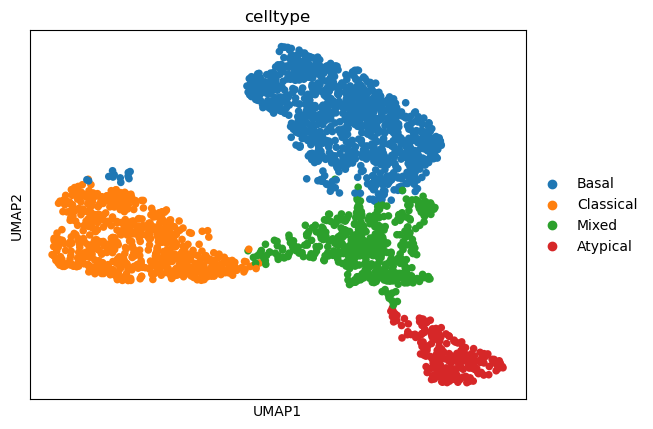

In [4]:
# visual inspection — loaded data
sc.pl.umap(adata, color = 'celltype', size = 120)

inferring a principal tree --> parameters used 
    200 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:  20%|██        | 10/50 [00:01<00:05,  7.78it/s]
    converged
    finished (0:00:01) 

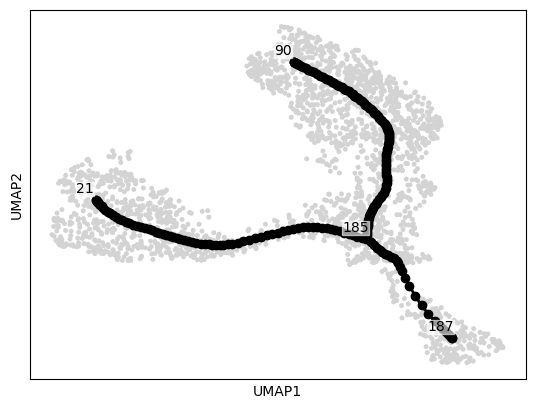

--> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.


In [5]:
# fit principal tree to cell-state manifold
# tune Nodes, ppt_lambda, ppt_sigma to balance
# over/underfitting
scf.tl.tree(adata, method = 'ppt', Nodes = 200,
            ppt_lambda = 2000, ppt_sigma = .5,
            use_rep = 'X_umap', seed = 1,
            plot = True, basis = 'umap')

In [6]:
# set putative root
# use biological priors
# e.g. mixed population
scf.tl.root(adata, 185)

node 185 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [7]:
# infer cell-state gradients
scf.tl.pseudotime(adata)

projecting cells onto the principal graph
    finished (0:00:02) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


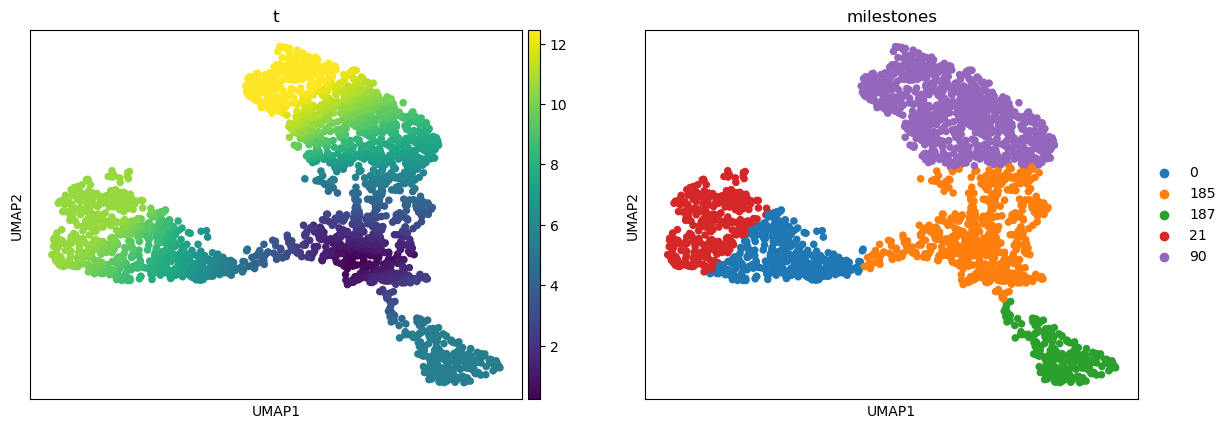

In [8]:
# visual inspection — manifold/gradients
c = ['t', 'milestones']
sc.pl.umap(adata, color = c, size = 120)

/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


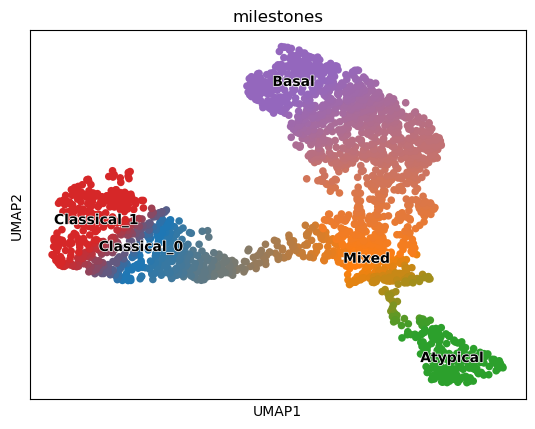

In [9]:
# rename milestones -> visual inspection
scf.tl.rename_milestones(adata, new = {
    '0'   : 'Classical_0',
    '185' : 'Mixed',
    '187' : 'Atypical',
    '21'  : 'Classical_1',
    '90'  : 'Basal'})
scf.pl.milestones(adata, basis = 'umap',
                  annotate = True, s = 120)

In [10]:
# save manifold to h5ad file
adata.write(os.path.join(pth_in, 'manifold.h5ad'))